<a href="https://colab.research.google.com/github/michael-zhang0/A05-pca/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sihan Michael Zhang

**Date:** 10/21/26

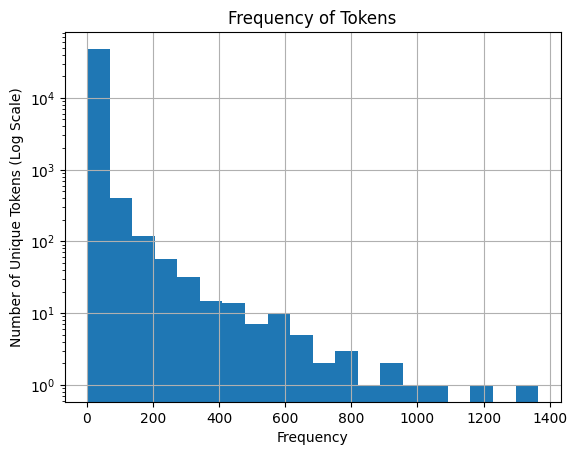

training r^2: 0.768699350041784
test r^2: 0.6516549296925569
background-image:   -1.137598
aging                1.043082
localized            0.777854
helvetica,           0.660271
reversing           -0.580435
dtype: float64


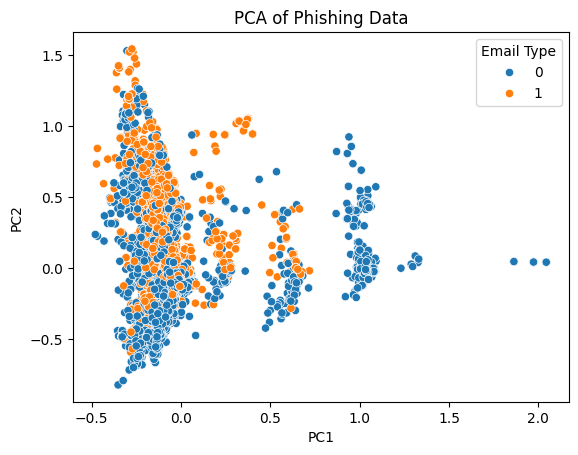

training r^2: 0.767997443340547
test r^2: 0.652182524249332


In [4]:
# Your Phase 1 solution to the problem goes here.
# Q1
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = list(token_count.values())

pd.Series(frequencies).hist(bins=20)
# linear scale puts everything into pretty much one bucket
plt.yscale('log')
plt.xlabel('Frequency')
plt.ylabel('Number of Unique Tokens (Log Scale)')
plt.title('Frequency of Tokens')
plt.show()
# The distribution of token frequencies is very right-skewed. Most unique tokens
# occur very infrequently, while a small number occur hundreds to over a
# thousand times. The number of tokens drops very sharply as frequency increases
# which causes the long right tail.

# Q2
df = pd.read_parquet('data/Phishing_clean.parquet')
x = df.drop(columns=['Email Type'])
y = df['Email Type']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,
                                                    random_state=1)
lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred_train = lr.predict(x_train)
y_pred_test = lr.predict(x_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
print(f'training r^2: {r2_train}')
print(f'test r^2: {r2_test}')
# training r^2: 0.768699350041784
# test r^2: 0.6516549296925569


coefficients = pd.Series(lr.coef_, index=x.columns)
top_words = coefficients.reindex(coefficients.abs().
                                 sort_values(ascending=False).index)
print(top_words.head())
# The words with the largest coefficients were background-image:, aging,
# localized, helvetica,, and reversing. The negative coefficient words are
# associated with legitimate emails while the positive coefficient words are
# associated with phishing emails.

# Q3
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x)

pca_df = pd.DataFrame(x_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type')
plt.title('PCA of Phishing Data')
plt.show()
# There is heavy overlap between roughly PC1 values of -0.5 to 0.7. The phishing
# emails are mostly concentrated around lower PC1 and higher PC2 values, while
# the legitimate emails are heavily concentrated between -0.5 and 0 for PC1,
# and exclusively legitimate emails remain past 0.7 for PC1. This basically
# says that the first two principal components capture some differences between
# email types, but there is still significant overlap which would make it hard
# to distinguish phishing from legitimate using only these two components.

# Q4
pca = PCA(n_components=2610)
x_pca = pca.fit_transform(x)
x_train, x_test, y_train, y_test = train_test_split(x_pca, y, test_size=0.2,
                                                    random_state=1)
lr = LinearRegression()
lr.fit(x_train, y_train)

y_pred_train = lr.predict(x_train)
y_pred_test = lr.predict(x_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
print(f'training r^2: {r2_train}')
print(f'test r^2: {r2_test}')
# training r^2: 0.767997443340547
# test r^2: 0.652182524249332
# The PCA regression had an R^2 of 0.7680 on training and 0.6522 on testing.
# The original linear regression had 0.7687 on training and 0.6517 on testing.
# The PCA regression has a slightly lower training R^2 but slightly higher
# testing R^2, indicating a very small improvement in generalization. This shows
# that removing the lowest-variance principle components still kept most of the
# predictive information while possibly reducing some noise.

# Q5
# The advantage of using principal components is that they reduce the number of
# features while still keeping most of the variation in the original data.
# Principal components are also uncorrelated, which helps reduce
# multicollinearity and can make the regression more stable and less likely to
# overfit. Here, PCA reduced the features from 2711 to 2610 with pretty much the
# same performance, with the only difference being a slight decrease in training
# and a slight increase in testing.

In [1]:
!git clone https://github.com/michael-zhang0/A05-pca.git
%cd A05-pca


Cloning into 'A05-pca'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 13 (delta 1), reused 0 (delta 0), pack-reused 10 (from 1)
Receiving objects: 100% (13/13), 1.57 MiB | 12.53 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/A05-pca


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]